In [1]:
import os
import platform
import sys
import tarfile
import urllib.request
from pathlib import Path

EPLUS_VERSION: str = "25.1.0"
EPLUS_BUILD: str = "68a4a7c774"
EPLUS_INSTALL_DIR: Path = Path(os.environ.get("EPLUS_INSTALL_DIR", Path.home() / ".local" / "energyplus"))


def is_energyplus_dir(path: Path) -> bool:
    return (path / "energyplus").exists() and (path / "pyenergyplus").is_dir()


def energyplus_tarball_name() -> str:
    version_id: str = platform.freedesktop_os_release().get("VERSION_ID", "22.04")
    ubuntu: str = "24.04" if version_id.split(".")[0].isdigit() and int(version_id.split(".")[0]) >= 24 else "22.04"
    arch: str = "arm64" if platform.machine() in ("aarch64", "arm64") else "x86_64"
    return f"EnergyPlus-{EPLUS_VERSION}-{EPLUS_BUILD}-Linux-Ubuntu{ubuntu}-{arch}"


def find_or_install_energyplus() -> Path:
    env_path: str | None = os.environ.get("EPLUS_PATH")
    if env_path and is_energyplus_dir(Path(env_path)):
        return Path(env_path)
    for candidate in sorted(EPLUS_INSTALL_DIR.glob(f"EnergyPlus-{EPLUS_VERSION}*")):
        if is_energyplus_dir(candidate):
            return candidate

    if platform.system() != "Linux":
        raise RuntimeError("This notebook targets Linux; install EnergyPlus manually and set EPLUS_PATH.")
    name: str = energyplus_tarball_name()
    url: str = f"https://github.com/NREL/EnergyPlus/releases/download/v{EPLUS_VERSION}/{name}.tar.gz"
    EPLUS_INSTALL_DIR.mkdir(parents=True, exist_ok=True)
    archive: Path = EPLUS_INSTALL_DIR / f"{name}.tar.gz"
    print(f"Downloading {url}")
    urllib.request.urlretrieve(url, archive)
    with tarfile.open(archive) as tar:
        tar.extractall(EPLUS_INSTALL_DIR, filter="tar")  # official archive; keeps its library symlinks
    archive.unlink()

    for candidate in sorted(EPLUS_INSTALL_DIR.glob(f"EnergyPlus-{EPLUS_VERSION}*")):
        if is_energyplus_dir(candidate):
            return candidate
    raise RuntimeError(f"EnergyPlus was extracted to {EPLUS_INSTALL_DIR}, but no installation directory was found.")


EPLUS_SYSTEM_LIBRARIES: dict[str, str] = {"X11": "libx11-6", "expat": "libexpat1", "gomp": "libgomp1"}


def check_system_libraries() -> None:
    import ctypes.util

    missing: list[str] = [apt for lib, apt in EPLUS_SYSTEM_LIBRARIES.items() if ctypes.util.find_library(lib) is None]
    if missing:
        raise RuntimeError(
            f"EnergyPlus needs system libraries that are not installed: {missing}. "
            f"Install them with:  sudo apt-get update && sudo apt-get install -y {' '.join(missing)}"
        )


check_system_libraries()
EPLUS_PATH: Path = find_or_install_energyplus()
os.environ["EPLUS_PATH"] = str(EPLUS_PATH)
os.environ["PYTHONPATH"] = os.pathsep.join(p for p in (str(EPLUS_PATH), os.environ.get("PYTHONPATH", "")) if p)
if str(EPLUS_PATH) not in sys.path:
    sys.path.insert(0, str(EPLUS_PATH))
print(f"EnergyPlus: {EPLUS_PATH}")

EnergyPlus: /home/sagemaker-user/.local/energyplus/EnergyPlus-25.1.0-68a4a7c774-Linux-Ubuntu24.04-x86_64


## 1. Imports

In [2]:
from __future__ import annotations

import json
import os
import pickle
import time
from collections.abc import Callable
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any, Final, TypeAlias

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
import sinergym
import torch
import torch.nn as nn
from IPython.display import display
from sinergym.utils.rewards import BaseReward
from stable_baselines3 import DQN, PPO
from stable_baselines3.common.base_class import BaseAlgorithm
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor
from stable_baselines3.common.utils import set_random_seed
from stable_baselines3.common.vec_env import DummyVecEnv, SubprocVecEnv, VecEnv, VecNormalize

In [3]:
SEED: Final[int] = 42
EVAL_SEED: Final[int] = 31415

CLIMATES: Final[tuple[str, ...]] = ("hot", "mixed", "cool")
TRAIN_CLIMATE: Final[str] = "mixed"
TRAIN_ENV_ID: Final[str] = f"Eplus-5zone-{TRAIN_CLIMATE}-discrete-stochastic-v1"
EVAL_ENV_IDS: Final[dict[str, str]] = {climate: f"Eplus-5zone-{climate}-discrete-v1" for climate in CLIMATES}

TIMESTEPS_PER_HOUR: Final[int] = 4
STEPS_PER_DAY: Final[int] = 24 * TIMESTEPS_PER_HOUR
STEPS_PER_EPISODE: Final[int] = 365 * STEPS_PER_DAY  # 35,040 simulation steps

ACTION_REPEAT: Final[int] = TIMESTEPS_PER_HOUR  # one decision per hour
DECISIONS_PER_DAY: Final[int] = STEPS_PER_DAY // ACTION_REPEAT
DECISIONS_PER_EPISODE: Final[int] = STEPS_PER_EPISODE // ACTION_REPEAT  # 8,760

OPERATING_HOURS: Final[tuple[int, int]] = (8, 18)  # [open, close)
WORKDAYS: Final[frozenset[int]] = frozenset({2, 3, 4, 5, 6})  # EnergyPlus day_of_week: 1 = Sunday … 7 = Saturday
PRECONDITION_HOURS: Final[int] = 1  # used by the rule-based baseline only

DQN_TRAIN_EPISODES: Final[int] = 20  # simulated years (175,200 decisions)
PPO_TRAIN_EPISODES: Final[int] = 50  # simulated years (438,000 decisions)

DEVICE: Final[torch.device] = torch.device("cpu")

RETRAIN: Final[bool] = False  # True: ignore cached models and train again
REEVALUATE: Final[bool] = False  # True: ignore cached evaluation episodes


@dataclass(frozen=True)
class RunPaths:
    """Output locations for a single training run (one algorithm)."""

    root: Path

    @property
    def state(self) -> Path:
        return self.root / "training_state.json"

    @property
    def model(self) -> Path:
        return self.root / "final_model.zip"

    @property
    def vecnormalize(self) -> Path:
        return self.root / "vecnormalize.pkl"

    @property
    def checkpoint_model(self) -> Path:
        return self.root / "checkpoint_model.zip"

    @property
    def checkpoint_vecnormalize(self) -> Path:
        return self.root / "checkpoint_vecnormalize.pkl"

    @property
    def training_log(self) -> Path:
        return self.root / "training_episodes.csv"

    def make_dirs(self) -> None:
        self.root.mkdir(parents=True, exist_ok=True)


RESULTS_DIR: Final[Path] = (Path.cwd().parent / "results" / "cadence_v2").resolve()
FIGURE_DIR: Final[Path] = RESULTS_DIR / "figures"
EVAL_DIR: Final[Path] = RESULTS_DIR / "eval_episodes"
TENSORBOARD_DIR: Final[Path] = RESULTS_DIR / "tensorboard"
SIM_WORKDIR: Final[Path] = RESULTS_DIR / "sinergym_runs"

for directory in (FIGURE_DIR, EVAL_DIR, TENSORBOARD_DIR, SIM_WORKDIR):
    directory.mkdir(parents=True, exist_ok=True)

# Sinergym creates its simulation folders in the current working directory
os.chdir(SIM_WORKDIR)
set_random_seed(SEED)

missing_ids: list[str] = [env_id for env_id in (TRAIN_ENV_ID, *EVAL_ENV_IDS.values()) if env_id not in gym.envs.registry]

In [4]:
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#898781",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "xtick.color": "#898781",
        "ytick.color": "#898781",
        "lines.linewidth": 1.6,
        "legend.frameon": False,
    }
)

POLICY_COLORS: Final[dict[str, str]] = {
    "DQN": "#2a78d6",
    "PPO": "#eb6834",
    "Rule-based": "#1baf7a",
    "Fixed setpoint": "#eda100",
    "Random": "#e87ba4",
}
COMFORT_BAND_COLOR: Final[str] = "#cde2fb"
OPERATING_SHADE_COLOR: Final[str] = "#f0efec"

## Environment Construction


In [5]:
COMFORT_WINTER: Final[tuple[float, float]] = (20.0, 23.5)
COMFORT_SUMMER: Final[tuple[float, float]] = (23.0, 26.0)
SUMMER_START: Final[tuple[int, int]] = (6, 1)
SUMMER_END: Final[tuple[int, int]] = (9, 30)

ENERGY_WEIGHT: Final[float] = 0.5
LAMBDA_ENERGY: Final[float] = 1e-4
LAMBDA_TEMPERATURE: Final[float] = 1.0
OFF_HOURS_COMFORT_WEIGHT: Final[float] = 0.1

ACTION_SETPOINTS: Final[list[tuple[float, float]]] = [
    (12.0, 30.0), (13.0, 29.0), (14.0, 28.0), (15.0, 27.0), (16.0, 26.0),
    (17.0, 25.0), (18.0, 24.0), (19.0, 23.25), (20.0, 23.25), (21.0, 23.25),
]
N_ACTIONS: Final[int] = len(ACTION_SETPOINTS)
COMFORT_ACTION: Final[int] = 8
SETBACK_ACTION: Final[int] = 0

DAYS_BEFORE_MONTH: Final[npt.NDArray[np.int64]] = np.cumsum([0, 31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30])


def comfort_range(month: int, day: int) -> tuple[float, float]:
    return COMFORT_SUMMER if SUMMER_START <= (month, day) <= SUMMER_END else COMFORT_WINTER


def is_workday(day_of_week: int, holiday_index: int) -> bool:
    return day_of_week in WORKDAYS and holiday_index == 0


def is_operating(day_of_week: int, holiday_index: int, hour: int) -> bool:
    return is_workday(day_of_week, holiday_index) and OPERATING_HOURS[0] <= hour < OPERATING_HOURS[1]


def hours_until_open(day_of_week: int, holiday_index: int, hour: int) -> int:
    """Hours until the next opening (0 while operating), e.g. 62 on Friday 18:00. Future holidays are not known in advance."""
    if is_operating(day_of_week, holiday_index, hour):
        return 0
    for ahead in range(1, 8 * 24):
        days_ahead, future_hour = divmod(hour + ahead, 24)
        future_day: int = (day_of_week - 1 + days_ahead) % 7 + 1
        if is_operating(future_day, holiday_index if days_ahead == 0 else 0, future_hour):
            return ahead
    raise ValueError("No operating hour within a week")


def temperature_violation(temperature: float, low: float, up: float) -> float:
    return max(low - temperature, 0.0) + max(temperature - up, 0.0)


class CadenceReward(BaseReward):
    """Sinergym's linear reward with the comfort penalty scaled down outside operating hours."""

    def __init__(
        self,
        temperature_variables: list[str],
        energy_variables: list[str],
        energy_weight: float = ENERGY_WEIGHT,
        lambda_energy: float = LAMBDA_ENERGY,
        lambda_temperature: float = LAMBDA_TEMPERATURE,
        off_hours_comfort_weight: float = OFF_HOURS_COMFORT_WEIGHT,
    ) -> None:
        super().__init__()
        self.temperature_variables: list[str] = temperature_variables
        self.energy_variables: list[str] = energy_variables
        self.energy_weight: float = energy_weight
        self.lambda_energy: float = lambda_energy
        self.lambda_temperature: float = lambda_temperature
        self.off_hours_comfort_weight: float = off_hours_comfort_weight

    def __call__(self, obs_dict: dict[str, Any]) -> tuple[float, dict[str, Any]]:
        low, up = comfort_range(int(obs_dict["month"]), int(obs_dict["day_of_month"]))
        violation: float = sum(temperature_violation(float(obs_dict[v]), low, up) for v in self.temperature_variables)
        power: float = sum(float(obs_dict[v]) for v in self.energy_variables)
        operating: bool = is_operating(int(obs_dict["day_of_week"]), int(obs_dict["holiday_index"]), int(obs_dict["hour"]))
        comfort_weight: float = 1.0 if operating else self.off_hours_comfort_weight

        energy_term: float = -self.energy_weight * self.lambda_energy * power
        comfort_term: float = -(1.0 - self.energy_weight) * self.lambda_temperature * comfort_weight * violation
        return energy_term + comfort_term, {
            "energy_term": energy_term,
            "comfort_term": comfort_term,
            "total_power_demand": power,
            "total_temperature_violation": violation,
            "comfort_weight": comfort_weight,
        }


TIME_VARIABLES: Final[list[str]] = ["month", "day_of_month", "hour", "day_of_week", "holiday_index"]

REWARD_KWARGS: Final[dict[str, Any]] = {
    "temperature_variables": ["air_temperature"],
    "energy_variables": ["HVAC_electricity_demand_rate"],
}

### Observation features: `CadenceObservationWrapper`

`CadenceObservationWrapper` does two things:

1. **Hourly decisions:** one `step()` applies the action for `ACTION_REPEAT = 4` simulation steps and returns the summed
   reward. All four 15-minute records are returned in `info["raw_records"]`, so metrics keep the 15-minute resolution.
2. **Features:** the raw Sinergym observation is converted into **27 features** before it reaches the network:

| Group | Features | Why |
|---|---|---|
| Time | sin/cos of day-of-year, sin/cos of hour | Cyclic encoding: 23:00 and 00:00 are neighbours, 31 Dec and 1 Jan too |
| Schedule | `is_operating`, `is_workday`, `hours_until_open` | The agent must know **how long until the building opens** (also across weekends: Friday 18:00 → Monday 08:00 = 62 h) to learn pre-conditioning |
| Comfort | current `comfort_low`, `comfort_up`, `temp_below`, `temp_above` | The comfort range switches between winter and summer; the distance to the band is the quantity the reward penalises |
| Outdoor | temperature, humidity, wind speed, sin/cos wind direction, diffuse/direct solar radiation | Weather drives the thermal load |
| Zone | temperature, **temperature change over the last hour**, humidity, occupant count | Temperature trend (heating/cooling up or down) without frame stacking |
| Setpoints | heating, cooling | The current action's effect |
| Energy | CO₂ emissions, HVAC demand rate, HVAC meter | Energy cost of the current state |

The features are then standardised online by SB3's `VecNormalize` (running mean/std, clipped to ±10) for the RL agents.
The raw (named) variables, the action and the original reward of every simulation step are returned in `info`, so that
metrics are always computed from physical values.

In [6]:
# Canonical name -> Sinergym variable names to look for (first exact match wins, then substring match)
VARIABLE_CANDIDATES: Final[dict[str, tuple[str, ...]]] = {
    "month": ("month",),
    "day_of_month": ("day_of_month",),
    "hour": ("hour",),
    "day_of_week": ("day_of_week",),
    "holiday_index": ("holiday_index",),
    "outdoor_temperature": ("outdoor_temperature",),
    "outdoor_humidity": ("outdoor_humidity",),
    "wind_speed": ("wind_speed",),
    "wind_direction": ("wind_direction",),
    "diffuse_solar_radiation": ("diffuse_solar_radiation",),
    "direct_solar_radiation": ("direct_solar_radiation",),
    "heating_setpoint": ("heating_setpoint", "htg_setpoint"),
    "cooling_setpoint": ("cooling_setpoint", "clg_setpoint"),
    "air_temperature": ("air_temperature",),
    "air_humidity": ("air_humidity",),
    "occupancy": ("people_occupant", "people"),
    "co2_emission": ("co2_emission",),
    "hvac_power": ("HVAC_electricity_demand_rate",),
    "hvac_energy": ("total_electricity_HVAC",),
}

FEATURE_NAMES: Final[list[str]] = [
    "doy_sin", "doy_cos", "hour_sin", "hour_cos", "is_operating", "is_workday", "hours_until_open",
    "comfort_low", "comfort_up", "temp_below", "temp_above",
    "outdoor_temperature", "outdoor_humidity", "wind_speed", "wind_dir_sin", "wind_dir_cos",
    "diffuse_solar_radiation", "direct_solar_radiation",
    "air_temperature", "air_temperature_delta", "air_humidity", "occupancy",
    "heating_setpoint", "cooling_setpoint",
    "co2_emission", "hvac_power", "hvac_energy",
]
FEATURE_INDEX: Final[dict[str, int]] = {name: i for i, name in enumerate(FEATURE_NAMES)}


def resolve_variables(names: list[str]) -> dict[str, int]:
    """Map every canonical variable to its index in Sinergym's observation vector."""
    resolved: dict[str, int] = {}
    for canonical, candidates in VARIABLE_CANDIDATES.items():
        index: int | None = next((names.index(c) for c in candidates if c in names), None)
        if index is None:
            index = next((i for c in candidates for i, n in enumerate(names) if c.lower() in n.lower()), None)
        if index is None:
            raise KeyError(f"No observation variable for '{canonical}' (candidates {candidates}) in {names}")
        resolved[canonical] = index
    return resolved


class CadenceObservationWrapper(gym.Wrapper):

    def __init__(self, env: gym.Env) -> None:
        super().__init__(env)
        self.variable_names: list[str] = list(env.get_wrapper_attr("observation_variables"))
        self.variable_index: dict[str, int] = resolve_variables(self.variable_names)
        self.observation_space = gym.spaces.Box(-np.inf, np.inf, shape=(len(FEATURE_NAMES),), dtype=np.float32)
        self.previous_temperature: float | None = None

    def raw_dict(self, obs: npt.NDArray[np.float32]) -> dict[str, float]:
        return {name: float(obs[i]) for name, i in self.variable_index.items()}

    def features(self, raw: dict[str, float]) -> npt.NDArray[np.float32]:
        month, day, hour = int(raw["month"]), int(raw["day_of_month"]), int(raw["hour"])
        day_of_week, holiday_index = int(raw["day_of_week"]), int(raw["holiday_index"])
        day_of_year: int = int(DAYS_BEFORE_MONTH[month - 1]) + day
        low, up = comfort_range(month, day)
        temperature: float = raw["air_temperature"]
        delta: float = 0.0 if self.previous_temperature is None else temperature - self.previous_temperature
        self.previous_temperature = temperature
        wind_rad: float = np.deg2rad(raw["wind_direction"])

        values: dict[str, float] = {
            "doy_sin": np.sin(2 * np.pi * day_of_year / 365),
            "doy_cos": np.cos(2 * np.pi * day_of_year / 365),
            "hour_sin": np.sin(2 * np.pi * hour / 24),
            "hour_cos": np.cos(2 * np.pi * hour / 24),
            "is_operating": float(is_operating(day_of_week, holiday_index, hour)),
            "is_workday": float(is_workday(day_of_week, holiday_index)),
            "hours_until_open": hours_until_open(day_of_week, holiday_index, hour) / 24,
            "comfort_low": low,
            "comfort_up": up,
            "temp_below": max(low - temperature, 0.0),
            "temp_above": max(temperature - up, 0.0),
            "wind_dir_sin": np.sin(wind_rad),
            "wind_dir_cos": np.cos(wind_rad),
            "air_temperature_delta": delta,
        }
        for name in FEATURE_NAMES:
            if name not in values:
                values[name] = raw[name]
        return np.array([values[name] for name in FEATURE_NAMES], dtype=np.float32)

    def reset(self, **kwargs: Any) -> tuple[npt.NDArray[np.float32], dict[str, Any]]:
        obs, info = self.env.reset(**kwargs)
        self.previous_temperature = None
        info["raw_records"] = []
        return self.features(self.raw_dict(obs)), info

    def step(self, action: int) -> tuple[npt.NDArray[np.float32], float, bool, bool, dict[str, Any]]:
        total_reward: float = 0.0
        records: list[dict[str, float]] = []
        for _ in range(ACTION_REPEAT):
            obs, reward, terminated, truncated, info = self.env.step(action)
            total_reward += float(reward)
            records.append({**self.raw_dict(obs), "action": int(action), "reward": float(reward)})
            if terminated or truncated:
                break
        info["raw_records"] = records
        return self.features(records[-1]), total_reward, terminated, truncated, info


def make_cadence_env(env_id: str, env_name: str, monitor: bool = False) -> gym.Env:
    """Sinergym 5Zone environment with the Cadence reward, hourly decisions and features (+ Monitor for episode statistics)."""
    env: gym.Env = gym.make(
        env_id, env_name=env_name, time_variables=TIME_VARIABLES, reward=CadenceReward, reward_kwargs=REWARD_KWARGS
    )
    env = CadenceObservationWrapper(env)
    return Monitor(env) if monitor else env

### Metrics

All metrics are computed from the raw (physical) variables of one simulated year:

| Metric | Definition |
|---|---|
| Mean reward | Mean per-step `CadenceReward` over the year |
| Mean power demand (W) | Mean HVAC electricity demand rate |
| HVAC energy (kWh) | Σ power × 0.25 h / 1000 |
| Comfort violation, operational (%) | % of operating-hour steps (workdays 08:00 to 18:00) with the zone temperature outside the comfort range |
| Unoccupied excursion (%) | % of non-operating steps (nights, weekends, holidays) outside the comfort range |
| Mean violation, operational (°C) | Mean distance to the comfort band during operating hours (severity, not only frequency) |
| Occupied comfort violation (%) | % of steps with occupants present (> 0) outside the comfort range (schedule-independent check) |

In [7]:
def comfort_bounds(month: pd.Series, day: pd.Series) -> tuple[npt.NDArray[np.float64], npt.NDArray[np.float64]]:
    key: pd.Series = month * 100 + day
    summer: npt.NDArray[np.bool_] = (
        (key >= SUMMER_START[0] * 100 + SUMMER_START[1]) & (key <= SUMMER_END[0] * 100 + SUMMER_END[1])
    ).to_numpy()
    low = np.where(summer, COMFORT_SUMMER[0], COMFORT_WINTER[0])
    up = np.where(summer, COMFORT_SUMMER[1], COMFORT_WINTER[1])
    return low, up


def add_derived_columns(episode: pd.DataFrame) -> pd.DataFrame:
    episode = episode.copy()
    low, up = comfort_bounds(episode["month"].astype(int), episode["day_of_month"].astype(int))
    temperature: npt.NDArray[np.float64] = episode["air_temperature"].to_numpy()
    episode["comfort_low"] = low
    episode["comfort_up"] = up
    episode["violation"] = np.maximum(low - temperature, 0) + np.maximum(temperature - up, 0)
    hour: pd.Series = episode["hour"].astype(int)
    episode["workday"] = episode["day_of_week"].astype(int).isin(WORKDAYS) & (episode["holiday_index"].astype(int) == 0)
    episode["operating"] = episode["workday"] & (hour >= OPERATING_HOURS[0]) & (hour < OPERATING_HOURS[1])
    day_of_year: npt.NDArray[np.int64] = DAYS_BEFORE_MONTH[episode["month"].astype(int) - 1] + episode["day_of_month"].astype(int)
    episode["day_of_year"] = day_of_year
    new_hour: pd.Series = (episode[["month", "day_of_month", "hour"]].diff().abs().sum(axis=1) != 0).cumsum()
    quarter: pd.Series = episode.groupby(new_hour).cumcount().clip(upper=TIMESTEPS_PER_HOUR - 1)
    episode["time_days"] = day_of_year + (hour + quarter / TIMESTEPS_PER_HOUR) / 24
    return episode


def compute_metrics(episode: pd.DataFrame) -> dict[str, float]:
    episode = add_derived_columns(episode)
    outside: pd.Series = episode["violation"] > 0
    operating: pd.Series = episode["operating"]
    occupied: pd.Series = episode["occupancy"] > 0
    return {
        "mean_reward": float(episode["reward"].mean()),
        "mean_power_W": float(episode["hvac_power"].mean()),
        "hvac_energy_kWh": float(episode["hvac_power"].sum() / TIMESTEPS_PER_HOUR / 1000),
        "comfort_violation_op_pct": float(100 * outside[operating].mean()),
        "unoccupied_excursion_pct": float(100 * outside[~operating].mean()),
        "mean_violation_op_C": float(episode.loc[operating, "violation"].mean()),
        "occupied_violation_pct": float(100 * outside[occupied].mean()) if occupied.any() else float("nan"),
    }


METRIC_LABELS: Final[dict[str, str]] = {
    "mean_reward": "Mean reward",
    "mean_power_W": "Mean power demand (W)",
    "hvac_energy_kWh": "HVAC energy (kWh)",
    "comfort_violation_op_pct": "Comfort violation, operational (%)",
    "unoccupied_excursion_pct": "Unoccupied excursion (%)",
    "mean_violation_op_C": "Mean violation, operational (°C)",
    "occupied_violation_pct": "Occupied comfort violation (%)",
}

### Environment probe

Builds the training environment once, prints the spaces and the variable mapping, and runs the **fixed-setpoint**
policy for the first two weeks of January (14 × 24 hourly decisions) to check the simulation, the reward and the feature wrapper.

#==============================================================================================#
[ENVIRONMENT] (INFO) : Creating Gymnasium environment.
[ENVIRONMENT] (INFO) : Name: cadence-probe
#==============================================================================================#
[MODEL] (INFO) : Working directory created: /home/sagemaker-user/reinforcment-learning/assignment3/notebooks/cadence-probe-res9
[MODEL] (INFO) : Model Config is correct.
[MODEL] (INFO) : Building model Output:Variable updated with defined variable names.
[MODEL] (INFO) : Updated building model Output:Meter with meter names.
[MODEL] (INFO) : Runperiod established.
[MODEL] (INFO) : Episode length (seconds): 31536000.0
[MODEL] (INFO) : timestep size (seconds): 900.0
[MODEL] (INFO) : timesteps per episode: 35040
[ENVIRONMENT] (INFO) : Environment created successfully.
[WRAPPER DiscretizeEnv] (INFO) : New Discrete Space and mapping: Discrete(10)
[WRAPPER DiscretizeEnv] (INFO) : Make sure that the action 

feature,doy_sin,doy_cos,hour_sin,hour_cos,is_operating,is_workday,hours_until_open,comfort_low,comfort_up,temp_below,...,direct_solar_radiation,air_temperature,air_temperature_delta,air_humidity,occupancy,heating_setpoint,cooling_setpoint,co2_emission,hvac_power,hvac_energy
last value,0.26,0.97,0.0,1.0,0.0,1.0,0.33,20.0,23.5,0.0,...,0.0,20.0,0.0,36.68,0.0,20.0,23.25,0.0,8385.719727,7547145.0


,air_temperature,outdoor_temperature,hvac_power,reward,violation
count,1344.00,1344.00,1344.00,1344.00,1344.00
mean,21.11,-1.74,5422.59,-0.27,0.00
std,1.47,4.99,3410.59,0.17,0.06
min,18.04,-12.00,87.04,-1.09,0.00
25%,20.00,-4.98,2676.21,-0.40,0.00
50%,20.00,-3.09,5111.68,-0.26,0.00
75%,23.25,0.76,7954.34,-0.13,0.00
max,23.25,12.28,19826.44,-0.00,1.96


day_of_year,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
day_of_week,3.0,4.0,5.0,6.0,7.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,1.0,2.0,3.0
holiday_index,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
workday,True,True,True,True,False,False,True,True,True,True,True,False,False,True,True


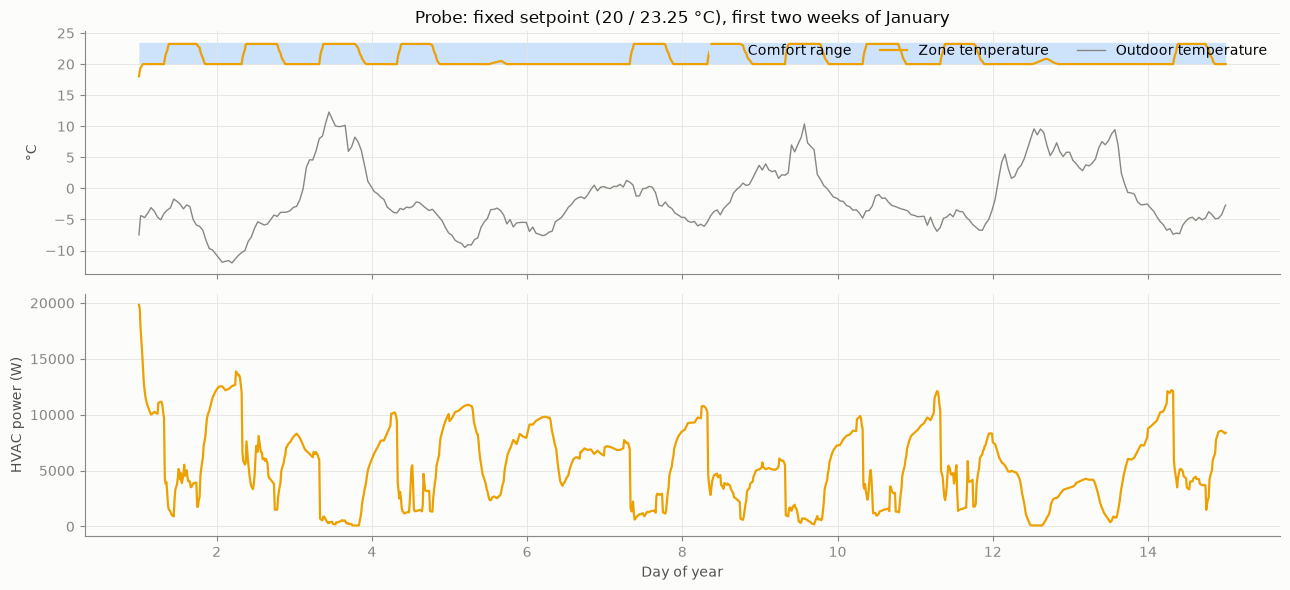

In [8]:
probe_env: CadenceObservationWrapper = make_cadence_env(TRAIN_ENV_ID, env_name="cadence-probe")

probe_obs, probe_info = probe_env.reset(seed=SEED)
probe_records: list[dict[str, float]] = []
for _ in range(14 * DECISIONS_PER_DAY):
    probe_obs, _, terminated, truncated, probe_info = probe_env.step(COMFORT_ACTION)
    probe_records.extend(probe_info["raw_records"])
    if terminated or truncated:
        break
probe_env.close()

probe_df: pd.DataFrame = add_derived_columns(pd.DataFrame(probe_records))
display(pd.DataFrame({"feature": FEATURE_NAMES, "last value": probe_obs}).set_index("feature").T.round(2))
display(probe_df[["air_temperature", "outdoor_temperature", "hvac_power", "reward", "violation"]].describe().round(2))
display(probe_df.groupby("day_of_year")[["day_of_week", "holiday_index", "workday"]].first().T)  # weekday check

fig, (ax_temp, ax_power) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax_temp.fill_between(probe_df["time_days"], probe_df["comfort_low"], probe_df["comfort_up"], color=COMFORT_BAND_COLOR, label="Comfort range", lw=0)
ax_temp.plot(probe_df["time_days"], probe_df["air_temperature"], color=POLICY_COLORS["Fixed setpoint"], label="Zone temperature")
ax_temp.plot(probe_df["time_days"], probe_df["outdoor_temperature"], color="#898781", lw=1.0, label="Outdoor temperature")
ax_temp.set_ylabel("°C")
ax_temp.set_title("Probe: fixed setpoint (20 / 23.25 °C), first two weeks of January")
ax_temp.legend(loc="upper right", ncols=3)
ax_power.plot(probe_df["time_days"], probe_df["hvac_power"], color=POLICY_COLORS["Fixed setpoint"])
ax_power.set_ylabel("HVAC power (W)")
ax_power.set_xlabel("Day of year")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "probe_fixed_setpoint.png", dpi=150)
plt.show()

## Model Definition

### Custom feature extractor

```
Input (27,)  engineered features, standardised by VecNormalize
  → Linear(27→256)  + LayerNorm + SiLU
  → Linear(256→256) + LayerNorm + SiLU   → 256 features
```

| Algorithm | Head(s) on top of the 256-d features |
|---|---|
| DQN | `Linear(256→128) + ReLU → Linear(128→10)`: Q-value per setpoint pair (+ target network, ε-greedy exploration) |
| PPO | Actor `Linear(256→128) + Tanh → Linear(128→10)`: action logits (categorical policy); Critic `Linear(256→128) + Tanh → Linear(128→1)`: state value. Extractor shared by actor and critic. |

In [9]:
class CadenceMLP(BaseFeaturesExtractor):

    def __init__(self, observation_space: gym.spaces.Box, features_dim: int = 256, hidden_dim: int = 256) -> None:
        super().__init__(observation_space, features_dim)
        n_inputs: int = int(np.prod(observation_space.shape))

        self.mlp: nn.Sequential = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_inputs, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, features_dim),
            nn.LayerNorm(features_dim),
            nn.SiLU(),
        )
        self._init_weights()

    def _init_weights(self) -> None:
        """Orthogonal initialisation (gain √2, as in SB3's default MLP policies), zero biases."""
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.orthogonal_(module.weight, gain=float(np.sqrt(2)))
                nn.init.zeros_(module.bias)

    def forward(self, observations: torch.Tensor) -> torch.Tensor:
        return self.mlp(observations)

In [10]:
probe_space: gym.spaces.Box = gym.spaces.Box(-np.inf, np.inf, shape=(len(FEATURE_NAMES),), dtype=np.float32)
probe_extractor: CadenceMLP = CadenceMLP(probe_space)
probe_output: torch.Tensor = probe_extractor(torch.zeros((1, len(FEATURE_NAMES))))

print(probe_extractor)
print(f"\nOutput shape         : {tuple(probe_output.shape)}")
print(f"Trainable parameters : {sum(p.numel() for p in probe_extractor.parameters()):,}")

CadenceMLP(
  (mlp): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=27, out_features=256, bias=True)
    (2): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (3): SiLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (6): SiLU()
  )
)

Output shape         : (1, 256)
Trainable parameters : 73,984


## 5. Hyperparameters

* Both agents: γ = 0.97 (hourly decisions), observation normalisation with `VecNormalize`.
* **DQN: 20 simulated years** (175,200 decisions). The replay buffer keeps the whole run; ε decays from 1.0 to 0.02 over
  the first 25 % of training (5 years), so every season is explored several times before the policy becomes greedy.
  One gradient step per decision (same number of updates as one per 4 steps in the 15-minute setting).
* **PPO: 50 simulated years** (438,000 decisions). Rollouts of 2,048 decisions (≈ 85 days), so each update sees several
  weather patterns; returns are normalised by `VecNormalize` because the magnitude of the reward changes strongly between
  seasons. A small entropy bonus keeps the policy stochastic early on.
* `n_envs > 1` runs several EnergyPlus simulations in parallel processes (`SubprocVecEnv`); the default is 1.

In [11]:
@dataclass(frozen=True)
class DQNConfig:

    n_envs: int = 1
    learning_rate: float = 1e-4
    buffer_size: int = 200_000
    learning_starts: int = 5_000
    batch_size: int = 256
    gamma: float = 0.97
    train_freq: int = 1
    gradient_steps: int = 1
    target_update_interval: int = 2_500
    exploration_fraction: float = 0.25
    exploration_initial_eps: float = 1.0
    exploration_final_eps: float = 0.02
    max_grad_norm: float = 10.0
    features_dim: int = 256
    hidden_dim: int = 256
    head_arch: tuple[int, ...] = (128,)
    normalize_reward: bool = False
    n_train_episodes: int = DQN_TRAIN_EPISODES


@dataclass(frozen=True)
class PPOConfig:

    n_envs: int = 1
    n_steps: int = 2_048
    batch_size: int = 256
    n_epochs: int = 10
    learning_rate: float = 3e-4
    clip_range: float = 0.2
    gamma: float = 0.97
    gae_lambda: float = 0.95
    ent_coef: float = 0.01
    vf_coef: float = 0.5
    max_grad_norm: float = 0.5
    features_dim: int = 256
    hidden_dim: int = 256
    head_arch: tuple[int, ...] = (128,)
    normalize_reward: bool = True
    n_train_episodes: int = PPO_TRAIN_EPISODES


AgentConfig: TypeAlias = DQNConfig | PPOConfig


@dataclass(frozen=True)
class Experiment:
    """One algorithm/configuration and where its results are stored."""

    name: str
    key: str
    algo_class: type[BaseAlgorithm]
    config: AgentConfig

    @property
    def paths(self) -> RunPaths:
        return RunPaths(RESULTS_DIR / self.key)


DQN_EXPERIMENT: Final[Experiment] = Experiment("DQN", "dqn", DQN, DQNConfig())
PPO_EXPERIMENT: Final[Experiment] = Experiment("PPO", "ppo", PPO, PPOConfig())
experiments: list[Experiment] = [DQN_EXPERIMENT, PPO_EXPERIMENT]

for experiment in experiments:
    experiment.paths.make_dirs()
    (experiment.paths.root / "config.json").write_text(json.dumps(asdict(experiment.config), indent=2))

display(pd.Series(asdict(DQN_EXPERIMENT.config), name="DQN").to_frame())
display(pd.Series(asdict(PPO_EXPERIMENT.config), name="PPO").to_frame())

,DQN
n_envs,1
learning_rate,0.0001
buffer_size,200000
learning_starts,5000
batch_size,256
gamma,0.97
train_freq,1
gradient_steps,1
target_update_interval,2500
exploration_fraction,0.25


,PPO
n_envs,1
n_steps,2048
batch_size,256
n_epochs,10
learning_rate,0.0003
clip_range,0.2
gamma,0.97
gae_lambda,0.95
ent_coef,0.01
vf_coef,0.5


## Training

In [12]:
@dataclass
class TrainingState:
    """Logs and bookkeeping of one training run, saved when the run finishes."""

    timesteps: int = 0
    completed: bool = False
    train_time_sec: float = 0.0
    episodes: list[dict[str, float]] = field(default_factory=list)

    @classmethod
    def load(cls, path: Path) -> "TrainingState":
        return cls(**json.loads(path.read_text())) if path.exists() else cls()

    def save(self, path: Path) -> None:
        """Atomic write: a kernel kill during the write never leaves a corrupted state file."""
        tmp_path: Path = path.with_name(path.name + ".tmp")
        tmp_path.write_text(json.dumps(asdict(self)))
        tmp_path.replace(path)


class EpisodeMetricsCallback(BaseCallback):
    """Per-year metric logging + checkpoint after every year + stop after a fixed number of training years."""

    def __init__(self, state: TrainingState, paths: RunPaths, n_episodes: int) -> None:
        super().__init__(verbose=0)
        self.state: TrainingState = state
        self.paths: RunPaths = paths
        self.n_episodes: int = n_episodes
        self.records: list[list[dict[str, float]]] = []
        self.start_time: float = 0.0

    def _on_training_start(self) -> None:
        self.records = [[] for _ in range(self.training_env.num_envs)]
        self.start_time = time.time()

    def _on_step(self) -> bool:
        for env_index, info in enumerate(self.locals["infos"]):
            self.records[env_index].extend(info.get("raw_records", []))
            episode_info: dict[str, float] | None = info.get("episode")
            if episode_info is not None:  # set by Monitor: original (unnormalised) return
                self._end_episode(env_index, episode_info)
        return len(self.state.episodes) < self.n_episodes

    def _end_episode(self, env_index: int, episode_info: dict[str, float]) -> None:
        metrics: dict[str, float] = compute_metrics(pd.DataFrame(self.records[env_index]))
        self.records[env_index] = []
        row: dict[str, float] = {
            "episode": len(self.state.episodes) + 1,
            "timesteps": self.num_timesteps,
            "return": float(episode_info["r"]),
            "length": int(episode_info["l"]),
            "elapsed_min": (time.time() - self.start_time) / 60,
            **metrics,
        }
        self.state.episodes.append(row)
        pd.DataFrame(self.state.episodes).to_csv(self.paths.training_log, index=False)
        self.model.save(self.paths.checkpoint_model)
        vecnormalize: VecNormalize | None = self.model.get_vec_normalize_env()
        if vecnormalize is not None:
            vecnormalize.save(self.paths.checkpoint_vecnormalize)
        print(
            f"  year {row['episode']:3d} | return {row['return']:10.1f} | power {row['mean_power_W']:7.1f} W | "
            f"comfort viol. (op) {row['comfort_violation_op_pct']:5.1f} % | excursion (off) {row['unoccupied_excursion_pct']:5.1f} % | "
            f"{row['elapsed_min']:6.1f} min"
        )


def make_training_venv(experiment: Experiment) -> VecNormalize:
    config: AgentConfig = experiment.config
    env_fns: list[Callable[[], gym.Env]] = [
        (lambda rank=rank: make_cadence_env(TRAIN_ENV_ID, env_name=f"cadence-{experiment.key}-train-{rank}", monitor=True))
        for rank in range(config.n_envs)
    ]
    venv: VecEnv = DummyVecEnv(env_fns) if config.n_envs == 1 else SubprocVecEnv(env_fns, start_method="forkserver")
    venv.seed(SEED)
    return VecNormalize(venv, norm_obs=True, norm_reward=config.normalize_reward, clip_obs=10.0, gamma=config.gamma)


def build_model(experiment: Experiment, venv: VecEnv) -> BaseAlgorithm:
    config: AgentConfig = experiment.config
    extractor_kwargs: dict[str, Any] = {
        "features_extractor_class": CadenceMLP,
        "features_extractor_kwargs": {"features_dim": config.features_dim, "hidden_dim": config.hidden_dim},
    }
    common: dict[str, Any] = {
        "env": venv,
        "seed": SEED,
        "device": DEVICE,
        "verbose": 0,
        "tensorboard_log": str(TENSORBOARD_DIR),
    }
    if isinstance(config, DQNConfig):
        return DQN(
            "MlpPolicy",
            learning_rate=config.learning_rate,
            buffer_size=config.buffer_size,
            learning_starts=config.learning_starts,
            batch_size=config.batch_size,
            gamma=config.gamma,
            train_freq=config.train_freq,
            gradient_steps=config.gradient_steps,
            target_update_interval=config.target_update_interval,
            exploration_fraction=config.exploration_fraction,
            exploration_initial_eps=config.exploration_initial_eps,
            exploration_final_eps=config.exploration_final_eps,
            max_grad_norm=config.max_grad_norm,
            policy_kwargs={**extractor_kwargs, "net_arch": list(config.head_arch)},
            **common,
        )
    return PPO(
        "MlpPolicy",
        n_steps=config.n_steps,
        batch_size=config.batch_size,
        n_epochs=config.n_epochs,
        learning_rate=config.learning_rate,
        clip_range=config.clip_range,
        gamma=config.gamma,
        gae_lambda=config.gae_lambda,
        ent_coef=config.ent_coef,
        vf_coef=config.vf_coef,
        max_grad_norm=config.max_grad_norm,
        policy_kwargs={
            **extractor_kwargs,
            "net_arch": {"pi": list(config.head_arch), "vf": list(config.head_arch)},
            "share_features_extractor": True,
        },
        **common,
    )


@dataclass
class TrainedRun:
    model: BaseAlgorithm
    state: TrainingState
    vecnormalize_path: Path


def train_or_load(experiment: Experiment) -> TrainedRun:
    paths: RunPaths = experiment.paths
    state: TrainingState = TrainingState.load(paths.state)
    if state.completed and paths.model.exists() and not RETRAIN:
        print(f"{experiment.name}: loading cached run ({len(state.episodes)} years, {state.timesteps:,} steps)")
        return TrainedRun(experiment.algo_class.load(paths.model, device=DEVICE), state, paths.vecnormalize)

    print(f"{experiment.name}: training for {experiment.config.n_train_episodes} simulated years")
    state = TrainingState()
    venv: VecNormalize = make_training_venv(experiment)
    model: BaseAlgorithm = build_model(experiment, venv)
    callback = EpisodeMetricsCallback(state, paths, experiment.config.n_train_episodes)

    start: float = time.time()
    total_timesteps: int = (
        experiment.config.n_train_episodes * DECISIONS_PER_EPISODE + experiment.config.n_envs * DECISIONS_PER_DAY
    )
    model.learn(total_timesteps=total_timesteps, callback=callback, tb_log_name=experiment.key, progress_bar=False)

    state.train_time_sec = time.time() - start
    state.timesteps = int(model.num_timesteps)
    state.completed = True
    model.save(paths.model)
    venv.save(paths.vecnormalize)
    state.save(paths.state)
    venv.close()
    print(f"{experiment.name}: finished in {state.train_time_sec / 60:.1f} min")
    return TrainedRun(model, state, paths.vecnormalize)

### 6.1 DQN

In [13]:
runs: dict[str, TrainedRun] = {}
runs["DQN"] = train_or_load(DQN_EXPERIMENT)

DQN: loading cached run (20 years, 175,200 steps)


### 6.2 PPO

In [14]:
runs["PPO"] = train_or_load(PPO_EXPERIMENT)

PPO: loading cached run (50 years, 438,000 steps)


### 6.3 Learning curves

Per-year training metrics (stochastic `mixed` weather; DQN includes ε-greedy exploration, PPO samples from its policy).

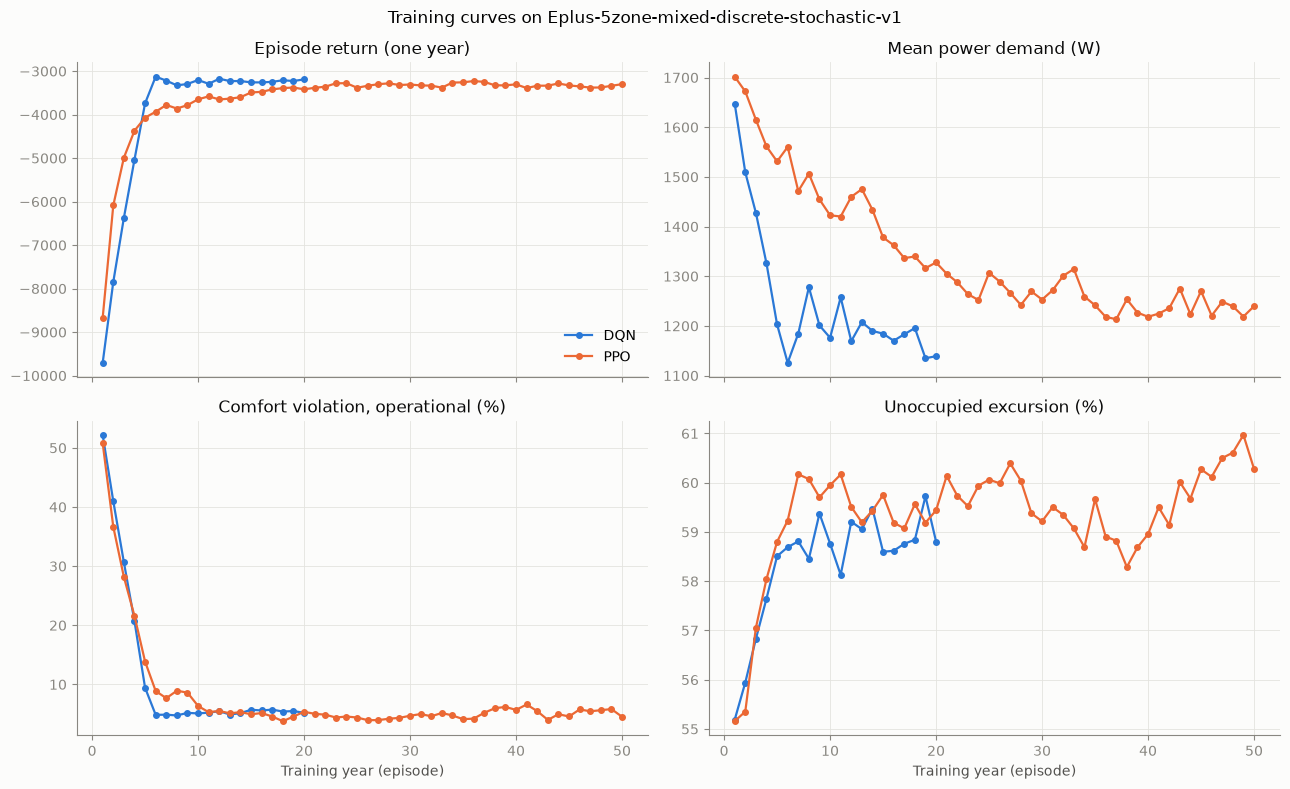

episode  timesteps   return  length  elapsed_min  mean_reward  \
DQN 17       18     157680 -3209.71    8760        19.49        -0.09   
    18       19     166440 -3227.29    8760        20.60        -0.09   
    19       20     175200 -3189.26    8760        21.71        -0.09   
PPO 47       48     420480 -3375.61    8760        25.40        -0.10   
    48       49     429240 -3337.18    8760        25.93        -0.10   
    49       50     438000 -3299.13    8760        26.46        -0.09   

        mean_power_W  hvac_energy_kWh  comfort_violation_op_pct  \
DQN 17       1195.60         10473.44                      5.40   
    18       1134.89          9941.64                      5.49   
    19       1139.02          9977.85                      5.19   
PPO 47       1239.41         10857.27                      5.63   
    48       1218.81         10676.81                      5.82   
    49       1239.62         10859.04                      4.52   

        unoccupied_excursion_pct  mean_violation_op_C  occupied_violation_pct  
DQN 17                     58.84                 0.03                    8.08  
    18                     59.72                 0.05                    8.97  
    19                     58.80                 0.04                    7.96  
PPO 47                     60.61                 0.04                    8.16  
    48                     60.97                 0.04                    9.54  
    49                     60.28                 0.03                    7.84

In [15]:
training_logs: dict[str, pd.DataFrame] = {name: pd.DataFrame(run.state.episodes) for name, run in runs.items()}
curve_metrics: list[str] = ["return", "mean_power_W", "comfort_violation_op_pct", "unoccupied_excursion_pct"]
curve_titles: dict[str, str] = {"return": "Episode return (one year)", **METRIC_LABELS}

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, metric in zip(axes.flat, curve_metrics):
    for name, log in training_logs.items():
        ax.plot(log["episode"], log[metric], color=POLICY_COLORS[name], marker="o", markersize=4, label=name)
    ax.set_title(curve_titles[metric])
for ax in axes[-1]:
    ax.set_xlabel("Training year (episode)")
axes[0, 0].legend()
fig.suptitle(f"Training curves on {TRAIN_ENV_ID}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "training_curves.png", dpi=150)
plt.show()

display(pd.concat({name: log.tail(3) for name, log in training_logs.items()}).round(2))

## Evaluation


In [16]:
Policy: TypeAlias = Callable[[npt.NDArray[np.float32]], int]


def random_policy(seed: int) -> Policy:
    rng: np.random.Generator = np.random.default_rng(seed)
    return lambda obs: int(rng.integers(N_ACTIONS))


def fixed_policy(action: int = COMFORT_ACTION) -> Policy:
    return lambda obs: action


def rule_based_policy() -> Policy:
    def act(obs: npt.NDArray[np.float32]) -> int:
        hours_to_open: float = float(obs[FEATURE_INDEX["hours_until_open"]]) * 24
        occupied_soon: bool = obs[FEATURE_INDEX["is_operating"]] > 0.5 or hours_to_open <= PRECONDITION_HOURS
        return COMFORT_ACTION if occupied_soon else SETBACK_ACTION

    return act


def trained_policy(run: TrainedRun) -> Policy:
    """Greedy policy on observations standardised with the training-time VecNormalize statistics."""
    with run.vecnormalize_path.open("rb") as f:
        vecnormalize: VecNormalize = pickle.load(f)
    mean: npt.NDArray[np.float64] = vecnormalize.obs_rms.mean
    std: npt.NDArray[np.float64] = np.sqrt(vecnormalize.obs_rms.var + vecnormalize.epsilon)
    clip: float = vecnormalize.clip_obs

    def act(obs: npt.NDArray[np.float32]) -> int:
        normalized: npt.NDArray[np.float32] = np.clip((obs - mean) / std, -clip, clip).astype(np.float32)
        action, _ = run.model.predict(normalized, deterministic=True)
        return int(action)

    return act


def run_episode(policy: Policy, env_id: str, env_name: str) -> pd.DataFrame:
    """One full simulated year; returns the raw variables, action and reward of every 15-minute simulation step."""
    env: CadenceObservationWrapper = make_cadence_env(env_id, env_name=env_name)
    obs, _ = env.reset(seed=EVAL_SEED)
    records: list[dict[str, float]] = []
    terminated = truncated = False
    while not (terminated or truncated):
        obs, _, terminated, truncated, info = env.step(policy(obs))
        records.extend(info["raw_records"])
    env.close()
    return pd.DataFrame(records)


def evaluate_or_load(name: str, policy_factory: Callable[[], Policy], climate: str) -> pd.DataFrame:
    key: str = name.lower().replace(" ", "_").replace("-", "_")
    path: Path = EVAL_DIR / f"{key}_{climate}.csv.gz"
    if path.exists() and not REEVALUATE:
        return pd.read_csv(path)
    start: float = time.time()
    episode: pd.DataFrame = run_episode(policy_factory(), EVAL_ENV_IDS[climate], env_name=f"cadence-eval-{key}-{climate}")
    episode.to_csv(path, index=False)
    print(f"{name:<15} | {climate:<5} | {len(episode):,} simulation steps | {time.time() - start:5.1f} s")
    return episode


policy_factories: dict[str, Callable[[], Policy]] = {
    "DQN": lambda: trained_policy(runs["DQN"]),
    "PPO": lambda: trained_policy(runs["PPO"]),
    "Rule-based": rule_based_policy,
    "Fixed setpoint": fixed_policy,
    "Random": lambda: random_policy(EVAL_SEED),
}

eval_episodes: dict[tuple[str, str], pd.DataFrame] = {
    (name, climate): evaluate_or_load(name, factory, climate)
    for name, factory in policy_factories.items()
    for climate in CLIMATES
}

### Metrics

In [17]:
results: pd.DataFrame = pd.DataFrame(
    [{"policy": name, "climate": climate, **compute_metrics(episode)} for (name, climate), episode in eval_episodes.items()]
)
results.to_csv(RESULTS_DIR / "evaluation_metrics.csv", index=False)

for climate in CLIMATES:
    table: pd.DataFrame = results[results["climate"] == climate].drop(columns="climate").set_index("policy")
    print(f"\n=== {climate} ===")
    display(table.rename(columns=METRIC_LABELS).round(2))

# Energy saving relative to the fixed-setpoint baseline (positive = less energy)
fixed_energy: pd.Series = results[results["policy"] == "Fixed setpoint"].set_index("climate")["hvac_energy_kWh"]
results["energy_saving_vs_fixed_pct"] = 100 * (1 - results["hvac_energy_kWh"] / results["climate"].map(fixed_energy))
display(
    results.pivot(index="policy", columns="climate", values="energy_saving_vs_fixed_pct")
    .loc[list(policy_factories), list(CLIMATES)]
    .round(1)
    .rename_axis(columns="Energy saving vs fixed setpoint (%)")
)


=== hot ===


,Mean reward,Mean power demand (W),HVAC energy (kWh),"Comfort violation, operational (%)",Unoccupied excursion (%),"Mean violation, operational (°C)",Occupied comfort violation (%)
policy,,,,,,,
DQN,-0.10,1786.07,15645.96,1.51,38.15,0.00,7.14
PPO,-0.09,1673.17,14656.97,0.56,37.19,0.00,4.66
Rule-based,-0.10,1784.23,15629.87,0.52,47.20,0.00,11.77
Fixed setpoint,-0.13,2345.66,20547.98,0.11,28.30,0.00,0.58
Random,-0.32,1755.63,15379.28,57.90,38.04,1.49,54.04



=== mixed ===


,Mean reward,Mean power demand (W),HVAC energy (kWh),"Comfort violation, operational (%)",Unoccupied excursion (%),"Mean violation, operational (°C)",Occupied comfort violation (%)
policy,,,,,,,
DQN,-0.09,1114.05,9759.11,3.85,58.87,0.02,6.48
PPO,-0.09,1170.46,10253.20,3.54,59.95,0.02,6.56
Rule-based,-0.10,1270.97,11133.66,1.43,63.08,0.01,7.94
Fixed setpoint,-0.13,2395.06,20980.69,0.47,40.66,0.00,1.25
Random,-0.29,1638.11,14349.83,56.77,55.00,1.27,50.78



=== cool ===


,Mean reward,Mean power demand (W),HVAC energy (kWh),"Comfort violation, operational (%)",Unoccupied excursion (%),"Mean violation, operational (°C)",Occupied comfort violation (%)
policy,,,,,,,
DQN,-0.07,647.13,5668.84,3.07,64.85,0.02,7.31
PPO,-0.07,665.55,5830.23,2.62,67.24,0.02,6.73
Rule-based,-0.07,654.23,5731.04,2.25,69.00,0.02,9.95
Fixed setpoint,-0.11,1758.43,15403.81,1.20,35.03,0.01,1.56
Random,-0.27,1025.35,8982.07,57.10,58.89,1.28,52.22


Energy saving vs fixed setpoint (%),hot,mixed,cool
policy,,,
DQN,23.9,53.5,63.2
PPO,28.7,51.1,62.2
Rule-based,23.9,46.9,62.8
Fixed setpoint,0.0,0.0,0.0
Random,25.2,31.6,41.7


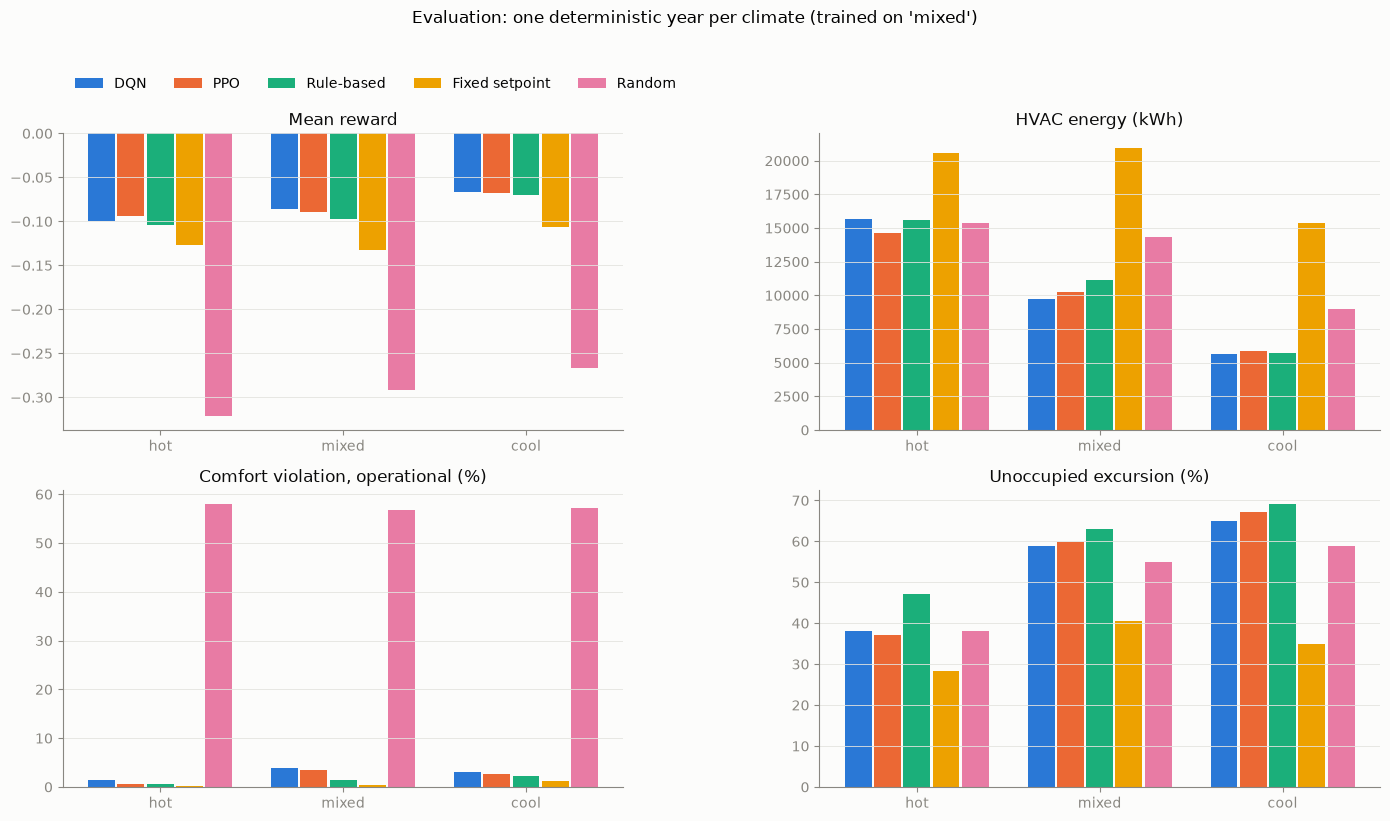

In [18]:
bar_metrics: list[str] = ["mean_reward", "hvac_energy_kWh", "comfort_violation_op_pct", "unoccupied_excursion_pct"]
policy_names: list[str] = list(policy_factories)
bar_width: float = 0.8 / len(policy_names)
x: npt.NDArray[np.float64] = np.arange(len(CLIMATES))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, metric in zip(axes.flat, bar_metrics):
    for i, name in enumerate(policy_names):
        values: pd.Series = results[results["policy"] == name].set_index("climate").loc[list(CLIMATES), metric]
        ax.bar(x + (i - (len(policy_names) - 1) / 2) * bar_width, values, width=bar_width * 0.92,
               color=POLICY_COLORS[name], label=name)
    ax.set_xticks(x, CLIMATES)
    ax.set_title(METRIC_LABELS[metric])
    ax.grid(axis="x", visible=False)
axes[0, 0].legend(ncols=len(policy_names), loc="lower left", bbox_to_anchor=(0, 1.1))
fig.suptitle("Evaluation: one deterministic year per climate (trained on 'mixed')", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "evaluation_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

### Energy-comfort trade-off

Each point is one policy in one climate. Lower-left is better (less energy, fewer comfort violations during operating
hours).

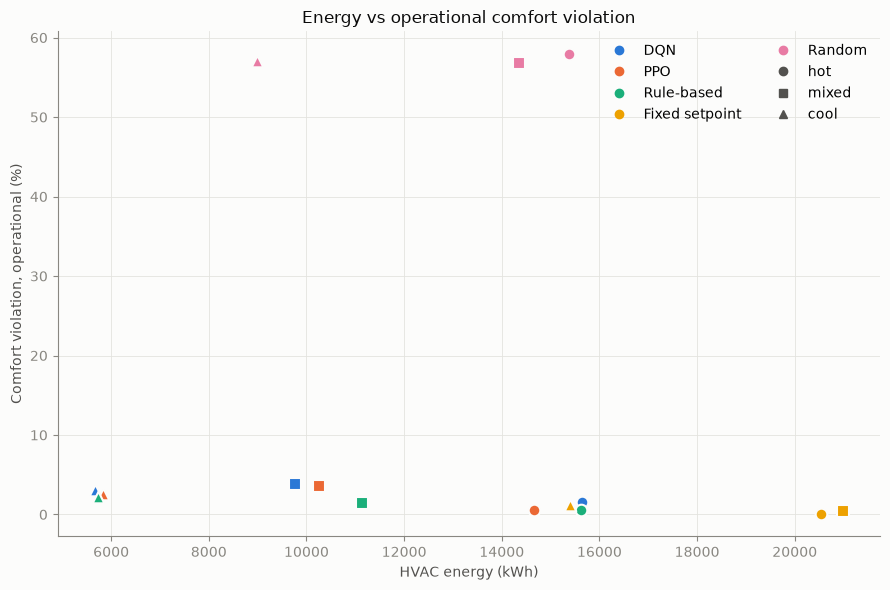

In [19]:
climate_markers: dict[str, str] = {"hot": "o", "mixed": "s", "cool": "^"}
fig, ax = plt.subplots(figsize=(9, 6))
for _, row in results.iterrows():
    ax.scatter(row["hvac_energy_kWh"], row["comfort_violation_op_pct"], s=70, color=POLICY_COLORS[row["policy"]],
               marker=climate_markers[row["climate"]], edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
policy_handles = [plt.Line2D([], [], color=c, marker="o", ls="", label=n) for n, c in POLICY_COLORS.items()]
climate_handles = [plt.Line2D([], [], color="#52514e", marker=m, ls="", label=c) for c, m in climate_markers.items()]
ax.legend(handles=policy_handles + climate_handles, loc="upper right", ncols=2)
ax.set_xlabel(METRIC_LABELS["hvac_energy_kWh"])
ax.set_ylabel(METRIC_LABELS["comfort_violation_op_pct"])
ax.set_title("Energy vs operational comfort violation")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "energy_comfort_tradeoff.png", dpi=150)
plt.show()

### Pre-conditioning: mean zone temperature by hour of day

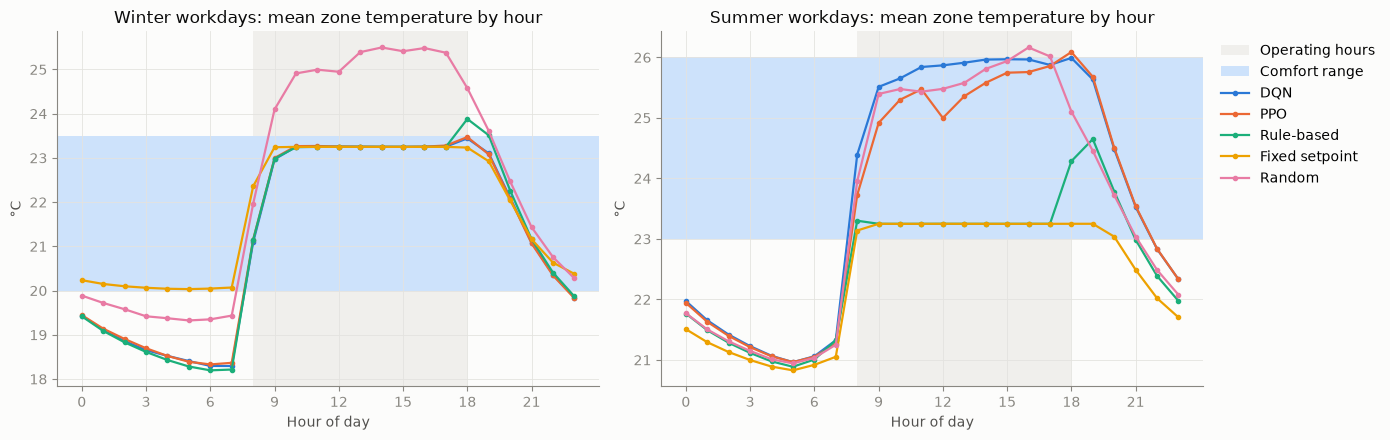

In [20]:
TRAJECTORY_CLIMATE: Final[str] = "mixed"
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, (season, summer) in zip(axes, (("Winter", False), ("Summer", True))):
    ax.axvspan(*OPERATING_HOURS, color=OPERATING_SHADE_COLOR, lw=0, label="Operating hours")
    low, up = COMFORT_SUMMER if summer else COMFORT_WINTER
    ax.axhspan(low, up, color=COMFORT_BAND_COLOR, lw=0, label="Comfort range")
    for name in policy_names:
        episode = add_derived_columns(eval_episodes[(name, TRAJECTORY_CLIMATE)])
        is_summer: pd.Series = episode["comfort_low"] == COMFORT_SUMMER[0]
        profile: pd.Series = episode[(is_summer == summer) & episode["workday"]].groupby("hour")["air_temperature"].mean()
        ax.plot(profile.index, profile.values, color=POLICY_COLORS[name], marker="o", markersize=3, label=name)
    ax.set_title(f"{season} workdays: mean zone temperature by hour")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("°C")
    ax.set_xticks(range(0, 24, 3))
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "hourly_temperature_profile.png", dpi=150)
plt.show()

### 7.6 Summary

In [21]:
summary_rows: list[dict[str, Any]] = []
for name in policy_names:
    policy_results: pd.DataFrame = results[results["policy"] == name]
    row: dict[str, Any] = {"Policy": name}
    for climate in CLIMATES:
        r: pd.Series = policy_results[policy_results["climate"] == climate].iloc[0]
        row[f"{climate}: reward"] = r["mean_reward"]
        row[f"{climate}: energy (kWh)"] = r["hvac_energy_kWh"]
        row[f"{climate}: comfort viol. op (%)"] = r["comfort_violation_op_pct"]
    if name in runs:
        state: TrainingState = runs[name].state
        row["Training years"] = len(state.episodes)
        row["Training steps"] = state.timesteps
        row["Training time (min)"] = state.train_time_sec / 60
    summary_rows.append(row)

summary: pd.DataFrame = pd.DataFrame(summary_rows).set_index("Policy")
summary.to_csv(RESULTS_DIR / "summary.csv")
display(summary.round(2))

,hot: reward,hot: energy (kWh),hot: comfort viol. op (%),mixed: reward,mixed: energy (kWh),mixed: comfort viol. op (%),cool: reward,cool: energy (kWh),cool: comfort viol. op (%),Training years,Training steps,Training time (min)
Policy,,,,,,,,,,,,
DQN,-0.10,15645.96,1.51,-0.09,9759.11,3.85,-0.07,5668.84,3.07,20.0,175200.0,21.72
PPO,-0.09,14656.97,0.56,-0.09,10253.20,3.54,-0.07,5830.23,2.62,50.0,438000.0,26.46
Rule-based,-0.10,15629.87,0.52,-0.10,11133.66,1.43,-0.07,5731.04,2.25,NaN,NaN,NaN
Fixed setpoint,-0.13,20547.98,0.11,-0.13,20980.69,0.47,-0.11,15403.81,1.20,NaN,NaN,NaN
Random,-0.32,15379.28,57.90,-0.29,14349.83,56.77,-0.27,8982.07,57.10,NaN,NaN,NaN
